# 6 — XGBoost
Same N/S/V/F benchmark. Hyperparameters/checkpoints use Validation; all four final models are compared on Test in notebook 9.


## Configuration and helpers


In [1]:
from pathlib import Path
import json, hashlib, random, time, copy, platform, importlib.metadata, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

VERSION_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'benchmark_config.json').is_file())
CONFIG = json.loads((VERSION_ROOT / 'benchmark_config.json').read_text(encoding='utf-8'))
RAW = Path(CONFIG['raw_directory'])
if not RAW.is_absolute():
    RAW = (VERSION_ROOT / RAW).resolve()
DATA = VERSION_ROOT / 'dataset/processed'
ARTIFACTS = VERSION_ROOT / 'model/artifacts'
REPORTS = VERSION_ROOT / 'model/reports'
CLASSES = CONFIG['classes']
N_CLASSES = len(CLASSES)
SEED = CONFIG['seed']
FS = 360
LEFT, RIGHT = CONFIG['left_samples'], CONFIG['right_samples']
WAVE_LENGTH = LEFT + RIGHT + 1
ALL_SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
ALL_LABEL_MAP = {s: i for i, symbols in enumerate(ALL_SYMBOLS) for s in symbols}
if CLASSES != ['N', 'S', 'V', 'F'] or LEFT < 18 or RIGHT < 180 or not CONFIG['offline_context']:
    raise ValueError('This version requires N/S/V/F, at least 50 ms before / 500 ms after FP, and offline context')

def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; รัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def macro_f1(y, predicted):
    return float(f1_score(y, predicted, labels=list(range(N_CLASSES)), average='macro', zero_division=0))

def class_weights(y, power=0.5, cap=20.0):
    counts = np.bincount(np.asarray(y, dtype=int), minlength=N_CLASSES)
    if (counts == 0).any():
        raise ValueError('Training data must contain all configured classes')
    values = np.minimum((len(y) / (N_CLASSES * counts)) ** power, cap)
    return values / np.average(values, weights=counts)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    except ImportError:
        pass

def environment():
    names = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'wfdb', 'pyarrow',
             'PyWavelets', 'xgboost', 'torch', 'optuna']
    versions = {}
    for name in names:
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = 'not installed'
    return {'python': platform.python_version(), 'platform': platform.platform(), 'packages': versions}

def validate_partitions(frame):
    if set(frame.split) != {'train', 'validation', 'test'}:
        raise ValueError('Require train, validation and test')
    if frame.beat_id.duplicated().any() or frame.groupby('patient_group').split.nunique().max() != 1:
        raise ValueError('Duplicate beat or patient leakage')
    for name, part in frame.groupby('split'):
        if set(part.class_id) != set(range(N_CLASSES)):
            raise ValueError(f'{name}: missing class')
    paired = frame.loc[frame.record_id.isin(['201', '202'])]
    if paired.patient_group.nunique() != 1 or paired.split.nunique() != 1:
        raise ValueError('201 and 202 must remain in one patient group and one partition')

def load_partition(split, *, allow_test=False):
    if split == 'test' and not allow_test:
        raise PermissionError('Test is evaluated only in notebook 9')
    manifest = read_json(DATA / 'prepared.json')
    if manifest['config_hash'] != sha256(VERSION_ROOT / 'benchmark_config.json'):
        raise ValueError('Configuration changed; rerun notebooks 1-4')
    for upstream in ['audit.json', 'split.json', 'preprocessing.json', 'feature_schema.json',
                     'inventory.parquet', 'split_inventory.parquet']:
        if sha256(DATA / upstream) != manifest['files'][upstream]:
            raise ValueError(f'Upstream artifact changed: {upstream}; rerun preparation')
    folder = DATA / split
    values = {}
    for key, name in [('meta', 'metadata.parquet'), ('wave', 'waveforms.npy'),
                      ('rr', 'rr.npy'), ('x', 'features_raw.npy')]:
        if sha256(folder / name) != manifest['files'][f'{split}/{name}']:
            raise ValueError(f'Artifact changed: {split}/{name}; rerun preparation')
        values[key] = pd.read_parquet(folder / name) if key == 'meta' else np.load(folder / name)
    m = values['meta']
    if not all(len(v) == len(m) for v in values.values()):
        raise ValueError('Array lengths differ')
    if not np.array_equal(m.waveform_index, np.arange(len(m))) or not m.split.eq(split).all():
        raise ValueError('Array/metadata alignment failed')
    if values['wave'].shape != (len(m), 2, WAVE_LENGTH) or not np.isfinite(values['wave']).all():
        raise ValueError('Invalid waveform shape or nonfinite waveform')
    values['y'] = m.class_id.to_numpy(dtype=np.int64)
    return values

def concatenate_partitions(parts):
    return {key: pd.concat([p[key] for p in parts], ignore_index=True) if key == 'meta'
            else np.concatenate([p[key] for p in parts]) for key in parts[0]}

def fit_transforms(part):
    feature_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    rr_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    rr_scaler = RobustScaler(quantile_range=(10., 90.))
    feature_imputer.fit(part['x'])
    rr_scaler.fit(rr_imputer.fit_transform(part['rr']))
    return {'feature_imputer': feature_imputer, 'rr_imputer': rr_imputer, 'rr_scaler': rr_scaler}

def transform_partition(part, transforms):
    result = dict(part)
    result['x'] = transforms['feature_imputer'].transform(part['x']).astype(np.float32)
    filled = transforms['rr_imputer'].transform(part['rr'])
    scaled = transforms['rr_scaler'].transform(filled)
    # Clipping bounds are fixed protocol constants; missing flags keep edge information.
    result['context'] = np.column_stack([np.clip(scaled, -10., 10.),
                                        ~np.isfinite(part['rr'])]).astype(np.float32)
    if not np.isfinite(result['x']).all() or not np.isfinite(result['context']).all():
        raise ValueError('Imputation/scaling produced nonfinite input')
    return result

def prepare_training(train_raw, validation_raw):
    transforms = fit_transforms(train_raw)
    return transform_partition(train_raw, transforms), transform_partition(validation_raw, transforms), transforms

def metrics(y, pred):
    report = classification_report(y, pred, labels=list(range(N_CLASSES)), target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(y, pred, labels=list(range(N_CLASSES)))
    normalized = np.divide(matrix, matrix.sum(1, keepdims=True), out=np.zeros_like(matrix, dtype=float),
                           where=matrix.sum(1, keepdims=True) != 0)
    return {'accuracy': float(accuracy_score(y, pred)), 'macro_f1': macro_f1(y, pred),
            'weighted_f1': float(report['weighted avg']['f1-score']),
            'balanced_accuracy': float(normalized.diagonal().mean()), 'per_class': report,
            'confusion_matrix': matrix.tolist(), 'normalized_confusion_matrix': normalized.tolist()}

def plot_trials(study, destination):
    frame = study.trials_dataframe()
    frame.to_csv(destination / 'trials.csv', index=False)
    complete = frame.loc[frame.state.eq('COMPLETE')].copy()
    if len(complete):
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(complete.number, complete.value, 'o-', alpha=.6, label='Validation Macro-F1')
        ax.plot(complete.number, complete.value.cummax(), linewidth=2, label='Best so far')
        ax.set(xlabel='Trial', ylabel='Macro-F1', ylim=(0, 1), title=study.study_name)
        ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(destination / 'tuning.png', dpi=160)
        plt.show(); plt.close(fig)


In [2]:
MODEL='xgb'
MODEL_REVISION=2


## Baseline hyperparameters


In [3]:
BASELINE_PARAMETERS={'max_depth': 5, 'eta': 0.03, 'min_child_weight': 3.0, 'subsample': 0.85, 'colsample_bytree': 0.8, 'lambda': 5.0, 'alpha': 0.001, 'gamma': 0.1, 'class_weight_power': 0.5}


## Optuna search space


In [4]:
SEARCH_SPACE={'max_depth': ['int', 3, 9], 'eta': ['log', 0.005, 0.15], 'min_child_weight': ['log', 1.0, 30.0], 'subsample': ['float', 0.6, 1.0], 'colsample_bytree': ['float', 0.5, 1.0], 'lambda': ['log', 0.1, 100.0], 'alpha': ['log', 1e-08, 10.0], 'gamma': ['float', 0.0, 5.0], 'class_weight_power': ['categorical', [0.0, 0.5, 1.0]]}


## Training controls


In [5]:
CPU_THREADS=max(1,min(8,(os.cpu_count() or 2)-1))
XGB_DEVICE='cuda'  # Set to 'cuda' in a supported XGBoost/CUDA environment.
N_TRIALS=20
MAX_BOOST_ROUNDS=3000
EARLY_STOPPING_ROUNDS=150
PRUNING_WARMUP=100
REFIT_ON_DEVELOPMENT=True
TRAINING_SIGNATURE={'max_rounds':MAX_BOOST_ROUNDS,'patience':EARLY_STOPPING_ROUNDS,'device':XGB_DEVICE,'seed':SEED}


## Model and training definitions


In [6]:
import xgboost as xgb

class OptunaCallback(xgb.callback.TrainingCallback):
    def __init__(self, trial):
        self.trial = trial
    def after_iteration(self, model, epoch, evals_log):
        if self.trial is not None:
            score = float(evals_log['validation']['macro_f1'][-1])
            self.trial.report(score, epoch)
            if self.trial.should_prune():
                raise optuna.TrialPruned(f'XGBoost pruned at round {epoch+1}')
        return False

def fit_model(parameters, train, validation=None, *, trial=None, fixed_steps=None):
    params = dict(parameters)
    power = params.pop('class_weight_power')
    weights = class_weights(train['y'], power)
    dtrain = xgb.DMatrix(train['x'], label=train['y'], weight=weights[train['y']], nthread=CPU_THREADS)
    evals, callbacks, history = [], [], {}
    if validation is not None:
        evals = [(xgb.DMatrix(validation['x'], label=validation['y'], nthread=CPU_THREADS), 'validation')]
        callbacks = [OptunaCallback(trial)]
    def metric(probabilities, data):
        return 'macro_f1', macro_f1(data.get_label().astype(int), probabilities.argmax(1))
    model = xgb.train({**params, 'objective': 'multi:softprob', 'num_class': N_CLASSES,
        'tree_method': 'hist', 'device': XGB_DEVICE, 'nthread': CPU_THREADS, 'seed': SEED,
        'eval_metric': 'mlogloss'}, dtrain, num_boost_round=fixed_steps or MAX_BOOST_ROUNDS,
        evals=evals, custom_metric=metric if validation is not None else None,
        maximize=True, early_stopping_rounds=EARLY_STOPPING_ROUNDS if validation is not None else None,
        callbacks=callbacks, evals_result=history, verbose_eval=False)
    best_steps = model.best_iteration + 1 if validation is not None else fixed_steps
    if validation is not None:
        model = model[:best_steps]
    return model, {'best_steps': int(best_steps), 'class_weights': weights.tolist(), 'device': XGB_DEVICE}, history

def predict_probabilities(model, part, batch_size=256):
    return model.predict(xgb.DMatrix(part['x'], nthread=CPU_THREADS))

def save_model(model, destination):
    model.save_model(destination / 'model.ubj')

def load_model(destination, parameters, context_dim):
    model = xgb.Booster()
    model.load_model(destination / 'model.ubj')
    model.set_param({'device': XGB_DEVICE, 'nthread': CPU_THREADS})
    return model


## Optuna and final refit definitions


In [7]:
import optuna
import gc

def suggest_parameters(trial):
    params = {}
    for name, specification in SEARCH_SPACE.items():
        kind = specification[0]
        if kind == 'categorical':
            params[name] = trial.suggest_categorical(name, specification[1])
        elif kind == 'int':
            params[name] = trial.suggest_int(name, specification[1], specification[2],
                                           step=specification[3] if len(specification)>3 else 1)
        else:
            params[name] = trial.suggest_float(name, specification[1], specification[2],
                                               log=kind == 'log')
    return params

def run_tuning(train, validation, transforms):
    prepared_hash = sha256(DATA / 'prepared.json')
    signature = hashlib.sha256(json.dumps({'prepared': prepared_hash, 'model': MODEL,
        'space': SEARCH_SPACE, 'revision': MODEL_REVISION, 'baseline': BASELINE_PARAMETERS,
        'controls': TRAINING_SIGNATURE}, sort_keys=True).encode()).hexdigest()
    run_id = signature[:16]
    destination = ARTIFACTS / MODEL / run_id
    destination.mkdir(parents=True, exist_ok=True)
    best_folder = destination / 'validation_best'
    best_folder.mkdir(exist_ok=True)
    storage = 'sqlite:///' + (destination / 'study.sqlite3').as_posix()
    study = optuna.create_study(study_name=f'{MODEL}_{run_id}', direction='maximize', storage=storage,
        load_if_exists=True, sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=15,
            multivariate=True, group=True),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=15,
            n_warmup_steps=PRUNING_WARMUP, interval_steps=5))
    if study.user_attrs.get('signature', signature) != signature:
        raise ValueError('Study protocol/data mismatch')
    study.set_user_attr('signature', signature)
    if not study.trials:
        study.enqueue_trial(BASELINE_PARAMETERS)
    def objective(trial):
        params = suggest_parameters(trial)
        seed_everything()
        started = time.perf_counter()
        model = None
        try:
            model, info, history = fit_model(params, train, validation, trial=trial)
            probabilities = predict_probabilities(model, validation)
            score = macro_f1(validation['y'], probabilities.argmax(1))
            info.update({'model': MODEL, 'parameters': params, 'validation_macro_f1': score,
                'trial': trial.number, 'train_seconds': time.perf_counter()-started,
                'prepared_hash': prepared_hash, 'signature': signature, 'classes': CLASSES,
                'context_dim': train['context'].shape[1], 'seed': SEED, 'environment': environment()})
            trial.set_user_attr('best_steps', info['best_steps'])
            trial.set_user_attr('train_seconds', info['train_seconds'])
            write_json(destination / f'history_{trial.number:04d}.json', history)
            previous = read_json(best_folder/'info.json') if (best_folder/'info.json').exists() else None
            if previous is None or score > previous['validation_macro_f1']:
                save_model(model, best_folder)
                joblib.dump(transforms, best_folder / 'transforms.joblib')
                write_json(best_folder/'info.json', info)
                frame = validation['meta'].copy()
                frame['predicted'] = probabilities.argmax(1)
                for i, name in enumerate(CLASSES): frame[f'score_{name}'] = probabilities[:,i]
                frame.to_parquet(best_folder/'validation_predictions.parquet', index=False)
            return score
        except RuntimeError as error:
            if 'out of memory' in str(error).lower():
                raise optuna.TrialPruned(f'Memory limit: {error}') from error
            raise
        finally:
            del model
            gc.collect()
            if MODEL in ['cnn','cnn_bilstm'] and torch.cuda.is_available(): torch.cuda.empty_cache()
    finished = sum(t.state.is_finished() for t in study.trials)
    remaining = max(0, N_TRIALS-finished)
    if remaining:
        study.optimize(objective, n_trials=remaining, n_jobs=1, gc_after_trial=True)
    if not (best_folder/'info.json').exists():
        raise RuntimeError('No completed trial')
    info = read_json(best_folder/'info.json')
    if not np.isclose(info['validation_macro_f1'], study.best_value):
        raise ValueError('Saved best checkpoint does not match Optuna study')
    plot_trials(study, destination)
    write_json(ARTIFACTS / MODEL / 'selected.json', {'run_id':run_id, 'path':str(destination.relative_to(ARTIFACTS)),
        'validation_macro_f1':info['validation_macro_f1'], 'parameters':info['parameters'],
        'prepared_hash':prepared_hash, 'signature':signature})
    return study, destination, info

def finalize_model(train_raw, validation_raw, destination, selected_info):
    final = destination / 'final'
    expected = {'signature':selected_info['signature'], 'refit_on_development':REFIT_ON_DEVELOPMENT,
                'selected_trial':selected_info['trial'], 'parameters':selected_info['parameters']}
    model_name = 'model.joblib' if MODEL == 'rf' else 'model.ubj' if MODEL == 'xgb' else 'model.pt'
    if all((final/name).exists() for name in ['info.json', 'transforms.joblib', model_name]):
        existing = read_json(final/'info.json')
        if all(existing.get(k)==v for k,v in expected.items()):
            print('Final model already saved:', final)
            return existing
    final.mkdir(exist_ok=True)
    if REFIT_ON_DEVELOPMENT:
        # Fixed hyperparameters and fixed epoch/round count; no Test is read during refit.
        development_raw = concatenate_partitions([train_raw, validation_raw])
        transforms = fit_transforms(development_raw)
        development = transform_partition(development_raw, transforms)
        seed_everything()
        model, fit_info, history = fit_model(selected_info['parameters'], development,
                                            fixed_steps=selected_info['best_steps'])
        save_model(model, final)
        info = {**selected_info, **fit_info, 'fit_partition':'train+validation', 'training_beats':len(development['y'])}
        write_json(final/'history.json', history)
    else:
        transforms = joblib.load(destination/'validation_best/transforms.joblib')
        model = load_model(destination/'validation_best', selected_info['parameters'], selected_info['context_dim'])
        save_model(model, final)
        info = {**selected_info, 'fit_partition':'train', 'training_beats':len(train_raw['y'])}
    joblib.dump(transforms, final/'transforms.joblib')
    info.update(expected)
    write_json(final/'info.json', info)
    del model
    gc.collect()
    if MODEL in ['cnn','cnn_bilstm'] and torch.cuda.is_available(): torch.cuda.empty_cache()
    return info


c:\Users\Kongkiat\miniconda3\envs\pattern\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Train and Validation


In [8]:
train_raw=load_partition('train')
validation_raw=load_partition('validation')
train,validation,transforms=prepare_training(train_raw,validation_raw)
print('Train:',len(train['y']),'Validation:',len(validation['y']))


Train: 42180 Validation: 10949


## Baseline and tuning — resumable study


c:\Users\Kongkiat\miniconda3\envs\pattern\Lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  optuna_warn(
[I 2026-10-14 15:11:53,807] A new study created in RDB with name: xgb_c670e1901e4dcae8
[I 2026-10-14 15:12:48,425] Trial 0 finished with value: 0.4622382631440286 and parameters: {'max_depth': 5, 'eta': 0.03, 'min_child_weight': 3.0, 'subsample': 0.85, 'colsample_bytree': 0.8, 'lambda': 5.0, 'alpha': 0.001, 'gamma': 0.1, 'class_weight_power': 0.5}. Best is trial 0 with value: 0.4622382631440286.
[I 2026-10-14 15:13:17,079] Trial 1 finished with value: 0.46058408786540234 and parameters: {'max_depth': 5, 'eta': 0.12684995383408856, 'min_child_weight': 12.057126287443763, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.5780093202212182, 'lambda': 0.2937538457632829, 'alpha': 3.3323645788192616e-08, 'gamma': 4.330880728874676, 'class_weight_power': 0.5}. Best is trial 0 with

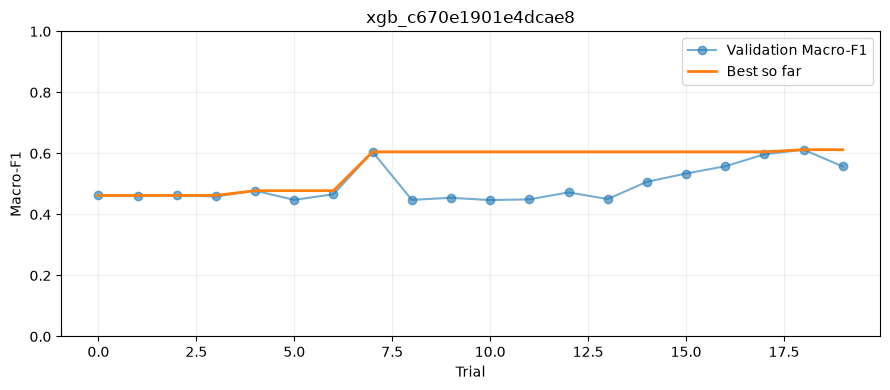

,max_depth,eta,min_child_weight,subsample,colsample_bytree,lambda,alpha,gamma,class_weight_power
0,3,0.05457,1.505648,0.938684,0.810836,0.240635,0.000002,2.822334,1.0


Best Validation Macro-F1: 0.6121212813540505


In [9]:
# Trial 0 uses the baseline; subsequent trials search the declared space.
# N_TRIALS is the total study budget, including completed/pruned trials and baseline.
study,destination,selected_info=run_tuning(train,validation,transforms)
display(pd.DataFrame([selected_info['parameters']]))
print('Best Validation Macro-F1:',selected_info['validation_macro_f1'])


## Refit selected settings on development


In [10]:
final_info=finalize_model(train_raw,validation_raw,destination,selected_info)
print('Final fit:',final_info['fit_partition'],'beats:',final_info['training_beats'])
print('Fixed epochs/rounds:',final_info['best_steps'])


Final fit: train+validation beats: 53129
Fixed epochs/rounds: 23


## Learning curves of the selected validation model
Curves use recorded training history: boosting rounds for XGBoost and epochs for neural networks. Only recorded metrics are plotted.
The checkpoint was selected on Validation before the final refit. The refit on Train + Validation has no independent validation curve.


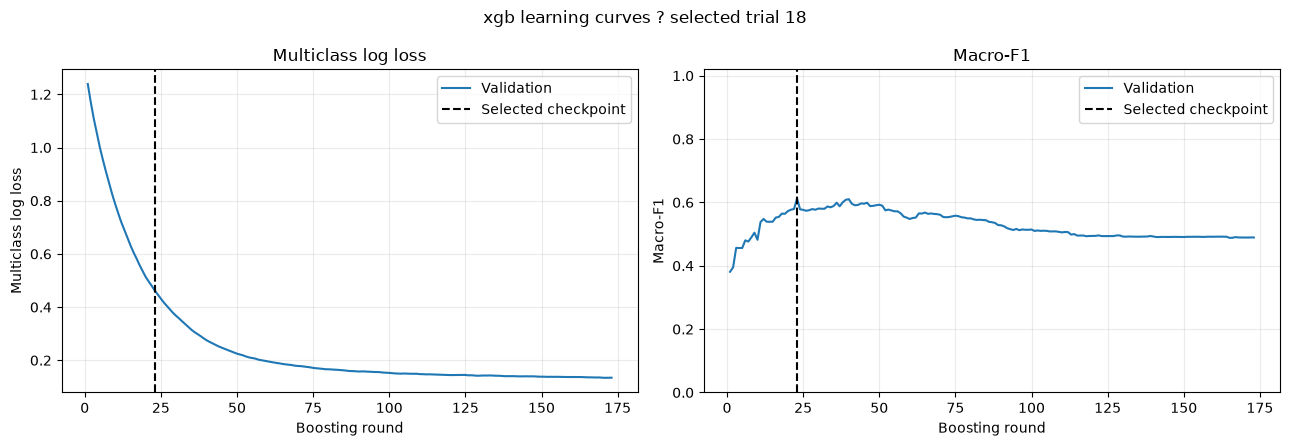

In [11]:
history = read_json(destination / f"history_{selected_info['trial']:04d}.json")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
if isinstance(history, list):
    frame = pd.DataFrame(history)
    axes[0].plot(frame['epoch'], frame['train_loss'], label='Train (augmented, weighted loss)')
    if 'validation_loss' in frame:
        axes[0].plot(frame['epoch'], frame['validation_loss'], label='Validation loss')
    axes[0].set(xlabel='Epoch', ylabel='Loss', title='Training loss')
    axes[1].plot(frame['epoch'], frame['validation_macro_f1'], label='Validation')
    if 'train_macro_f1' in frame:
        axes[1].plot(frame['epoch'], frame['train_macro_f1'], label='Train')
    axes[1].set(xlabel='Epoch', ylabel='Macro-F1', title='Validation performance', ylim=(0, 1.02))
else:
    for partition, values in history.items():
        for ax, metric, title in zip(axes, ['mlogloss', 'macro_f1'], ['Multiclass log loss', 'Macro-F1']):
            if metric in values:
                steps = np.arange(1, len(values[metric]) + 1)
                ax.plot(steps, values[metric], label=partition.title())
            ax.set(xlabel='Boosting round', ylabel=title, title=title)
    axes[1].set_ylim(0, 1.02)
for ax in axes:
    ax.axvline(selected_info['best_steps'], linestyle='--', color='black', label='Selected checkpoint')
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'{MODEL} learning curves ? selected trial {selected_info["trial"]}')
fig.tight_layout()
fig.savefig(destination / 'selected_history.png', dpi=160)
plt.show()
plt.close(fig)


## Hyperparameters used and final fit summary
Selected and final parameters, actual tree/round/epoch count, seed, device, and class weights from saved artifacts.


In [12]:
# Read the saved settings so the summary reflects the actual selected/final artifacts.
used_selected = read_json(destination / 'validation_best' / 'info.json')
used_final = read_json(destination / 'final' / 'info.json')
parameter_names = sorted(set(used_selected['parameters']) | set(used_final['parameters']))
hyperparameter_summary = pd.DataFrame({
    'parameter': parameter_names,
    'selected_validation_model': [repr(used_selected['parameters'].get(key)) for key in parameter_names],
    'final_model': [repr(used_final['parameters'].get(key)) for key in parameter_names],
}).set_index('parameter')
display(hyperparameter_summary)
hyperparameter_summary.to_csv(destination / 'hyperparameter_summary.csv')
step_name = {'rf': 'Number of trees', 'xgb': 'Boosting rounds', 'cnn': 'Epochs', 'cnn_bilstm': 'Epochs'}[MODEL]
fit_summary = pd.DataFrame({
    'selected_validation_model': {'Fit partition': 'train', step_name: used_selected['best_steps'],
        'Trial': used_selected['trial'], 'Seed': used_selected['seed'], 'Device': used_selected['device']},
    'final_model': {'Fit partition': used_final['fit_partition'], step_name: used_final['best_steps'],
        'Trial': used_final['selected_trial'], 'Seed': used_final['seed'], 'Device': used_final['device']},
})
display(fit_summary)
display(pd.DataFrame({'class': CLASSES, 'selected_class_weight': used_selected['class_weights'],
                      'final_class_weight': used_final['class_weights']}))
print('Selected Validation Macro-F1:', used_selected['validation_macro_f1'])
print('Final training beats:', used_final['training_beats'])


,selected_validation_model,final_model
parameter,,
alpha,2.283155845091793e-06,2.283155845091793e-06
class_weight_power,1.0,1.0
colsample_bytree,0.8108364933590647,0.8108364933590647
eta,0.054570456784154696,0.054570456784154696
gamma,2.8223337687426926,2.8223337687426926
lambda,0.2406345148683428,0.2406345148683428
max_depth,3,3
min_child_weight,1.5056477455353992,1.5056477455353992
subsample,0.9386839131136677,0.9386839131136677


,selected_validation_model,final_model
Fit partition,train,train+validation
Boosting rounds,23,23
Trial,18,18
Seed,42,42
Device,cuda,cuda


,class,selected_class_weight,final_class_weight
0,N,0.297576,0.305934
1,S,14.057147,14.671375
2,V,3.754799,3.849935
3,F,21.435650,22.069610


Selected Validation Macro-F1: 0.6121212813540505
Final training beats: 53129
